In [1]:
from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

In [2]:

# Configuración estética
plt.style.use("seaborn-v0_8-whitegrid")
plt.rcParams["font.family"] = "sans-serif"
plt.rcParams["font.size"] = 10
plt.rcParams["axes.titlesize"] = 12
plt.rcParams["axes.labelsize"] = 11

# ------------------------------------------------------------------------------
# 1. Búsqueda dinámica de la carpeta processed
# ------------------------------------------------------------------------------
CURRENT_DIR = Path().resolve()

if (CURRENT_DIR / "data" / "processed").exists():
  PROCESSED_DIR = CURRENT_DIR / "data" / "processed"
elif (CURRENT_DIR.parent / "data" / "processed").exists():
  PROCESSED_DIR = CURRENT_DIR.parent / "data" / "processed"
else:
  PROCESSED_DIR = next(CURRENT_DIR.glob("**/data/processed"), None)

if not PROCESSED_DIR or not PROCESSED_DIR.exists():
  raise FileNotFoundError(
      f"No se encontró 'data/processed'. Directorio actual: {CURRENT_DIR}"
  )

print(f"Directorio de datos detectado: {PROCESSED_DIR}")

# ------------------------------------------------------------------------------
# 2. Definición y carga de los datasets definitivos (prueba_final)
# ------------------------------------------------------------------------------
TAG_OFICIAL = "prueba_final"

hourly_file = (
    PROCESSED_DIR
    / f"air_quality_chile_2020_2026_consolidated_{TAG_OFICIAL}.parquet"
)
daily_file = PROCESSED_DIR / f"daily_modeling_gold_{TAG_OFICIAL}.parquet"

# Fallback automático en caso de que aún se use el tag sin sufijo
if not hourly_file.exists():
  candidatos_h = sorted(PROCESSED_DIR.glob("*consolidated*.parquet"))
  if candidatos_h:
    hourly_file = candidatos_h[-1]
  else:
    raise FileNotFoundError(
        f"No se encontró el dataset horario en: {PROCESSED_DIR}"
    )

if not daily_file.exists():
  candidatos_d = sorted(PROCESSED_DIR.glob("*daily_modeling_gold*.parquet"))
  if candidatos_d:
    daily_file = candidatos_d[-1]
  else:
    raise FileNotFoundError(
        f"No se encontró el dataset Gold diario en: {PROCESSED_DIR}"
    )

print(f"Cargando horario : {hourly_file.name}")
print(f"Cargando diario  : {daily_file.name}")

df_hourly = pd.read_parquet(hourly_file)
df_daily = pd.read_parquet(daily_file)

# Parseo de fechas
df_hourly["time_local"] = pd.to_datetime(df_hourly["time_local"])
df_daily["date_local"] = pd.to_datetime(df_daily["date_local"])

print(f"\n✓ Dataset horario: {df_hourly.shape[0]:,} registros")
print(
    f"✓ Dataset diario : {df_daily.shape[0]:,} días evaluados"
    f" ({df_daily['date_local'].min().date()} a"
    f" {df_daily['date_local'].max().date()})"
)

Directorio de datos detectado: C:\Users\chest\OneDrive\Documentos\Portafolio\Medicion contaminantes\data\processed
Cargando horario : air_quality_chile_2020_2026_consolidated_prueba_final.parquet
Cargando diario  : daily_modeling_gold_prueba_final.parquet

✓ Dataset horario: 237,984 registros
✓ Dataset diario : 7,775 días evaluados (2021-03-21 a 2026-10-13)


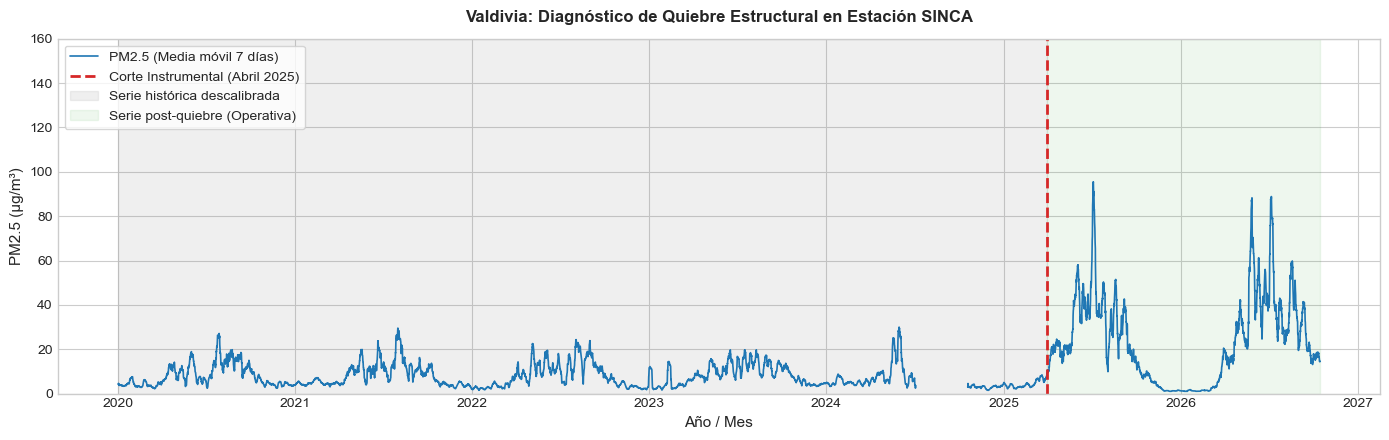

In [10]:
df_valdivia = df_hourly[df_hourly["city"] == "Valdivia"].copy().sort_values("time_local")

fig, ax = plt.subplots(figsize=(14, 4.5))

# Serie temporal de PM2.5 (media móvil semanal para visibilidad clara)
val_roll = df_valdivia.set_index("time_local")["pm2_5"].rolling("7D", min_periods=24).mean()

ax.plot(val_roll.index, val_roll.values, color="#1f77b4", lw=1.2, label="PM2.5 (Media móvil 7 días)")
ax.axvline(pd.Timestamp("2025-04-01"), color="#d62728", ls="--", lw=2, label="Corte Instrumental (Abril 2025)")

# Sombrear periodos para enfatizar el quiebre
ax.axvspan(val_roll.index.min(), pd.Timestamp("2025-04-01"), color="gray", alpha=0.12, label="Serie histórica descalibrada")
ax.axvspan(pd.Timestamp("2025-04-01"), val_roll.index.max(), color="#2ca02c", alpha=0.08, label="Serie post-quiebre (Operativa)")

ax.set_title("Valdivia: Diagnóstico de Quiebre Estructural en Estación SINCA", fontweight="bold", pad=12)
ax.set_ylabel("PM2.5 (µg/m³)")
ax.set_xlabel("Año / Mes")
ax.set_ylim(0, 160)
ax.legend(loc="upper left", frameon=True)

plt.tight_layout()
Path("docs/img").mkdir(parents=True, exist_ok=True)
plt.savefig("docs/img/quiebre_valdivia.png", dpi=300, bbox_inches="tight")
plt.show()

In [4]:
# ------------------------------------------------------------------------------
# Celda 3: Comparativa Global — Frecuencia de Alertas en Invierno (GEC)
# ------------------------------------------------------------------------------
UMBRAL_ALERTA = 50.0  # µg/m³ norma diaria
meses_gec = [5, 6, 7, 8]

# Filtrar meses invernales (Gestión de Episodios Críticos)
df_gec = df_daily[df_daily["month"].isin(meses_gec)].copy()

# Crear bandera de alerta del día si no viene calculada en el parquet
if "alerta_today" not in df_gec.columns:
    df_gec["alerta_today"] = (df_gec["pm25_mean_day"] >= UMBRAL_ALERTA).astype(int).where(df_gec["pm25_mean_day"].notna())

resumen_ciudades = df_gec.groupby("city").agg(
    dias_totales=("date_local", "count"),
    dias_alerta=("alerta_today", lambda x: (x == 1).sum()),
    pm25_promedio=("pm25_mean_day", "mean"),
    pm25_p95=("pm25_mean_day", lambda x: x.quantile(0.95)),
    temp_min_promedio=("temp_min_day_forecast", "mean"),
    viento_promedio=("wind_mean_day_forecast", "mean"),
).reset_index()

resumen_ciudades["tasa_alerta_pct"] = (
    resumen_ciudades["dias_alerta"] / resumen_ciudades["dias_totales"]
) * 100
resumen_ciudades = resumen_ciudades.sort_values("tasa_alerta_pct", ascending=False)

# Mostrar tabla estilizada
display(
    resumen_ciudades.style.format({
        "pm25_promedio": "{:.1f} µg/m³",
        "pm25_p95": "{:.1f} µg/m³",
        "temp_min_promedio": "{:.1f} °C",
        "viento_promedio": "{:.1f} km/h",
        "tasa_alerta_pct": "{:.1f}%",
    }).background_gradient(subset=["tasa_alerta_pct", "pm25_promedio"], cmap="YlOrRd")
)

,city,dias_totales,dias_alerta,pm25_promedio,pm25_p95,temp_min_promedio,viento_promedio,tasa_alerta_pct
0,Aysén,736,434,81.6 µg/m³,243.8 µg/m³,1.5 °C,4.2 km/h,59.0%
2,Temuco,717,266,47.3 µg/m³,115.5 µg/m³,4.5 °C,6.9 km/h,37.1%
1,Santiago,719,148,36.4 µg/m³,66.5 µg/m³,10.8 °C,4.4 km/h,20.6%
3,Valdivia,668,73,23.0 µg/m³,66.0 µg/m³,4.8 °C,5.1 km/h,10.9%


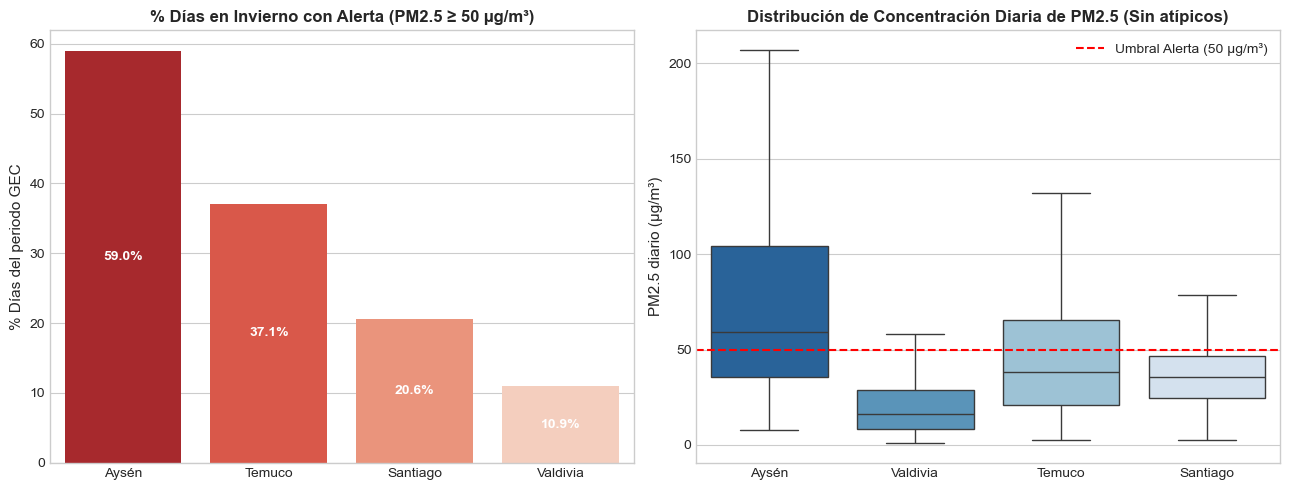

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

palette = ["#900C3F", "#C70039", "#FF5733", "#3357FF"]

# 1. Porcentaje de días en episodio crítico
sns.barplot(
    data=resumen_ciudades,
    x="city",
    y="tasa_alerta_pct",
    ax=axes[0],
    palette="Reds_r",
    hue="city",
    legend=False,
)
axes[0].set_title("% Días en Invierno con Alerta (PM2.5 ≥ 50 µg/m³)", fontweight="bold")
axes[0].set_ylabel("% Días del periodo GEC")
axes[0].set_xlabel("")
for p in axes[0].patches:
    axes[0].annotate(f"{p.get_height():.1f}%", (p.get_x() + p.get_width() / 2., p.get_height() / 2),
                     ha="center", va="center", color="white", fontweight="bold")

# 2. Distribución de concentraciones diarias
sns.boxplot(
    data=df_gec,
    x="city",
    y="pm25_mean_day",
    ax=axes[1],
    palette="Blues_r",
    hue="city",
    legend=False,
    showfliers=False,
)
axes[1].axhline(50, color="red", ls="--", lw=1.5, label="Umbral Alerta (50 µg/m³)")
axes[1].set_title("Distribución de Concentración Diaria de PM2.5 (Sin atípicos)", fontweight="bold")
axes[1].set_ylabel("PM2.5 diario (µg/m³)")
axes[1].set_xlabel("")
axes[1].legend(loc="upper right")

plt.tight_layout()
plt.savefig("docs/img/distribucion_pm25.png", dpi=300, bbox_inches="tight")
plt.show()

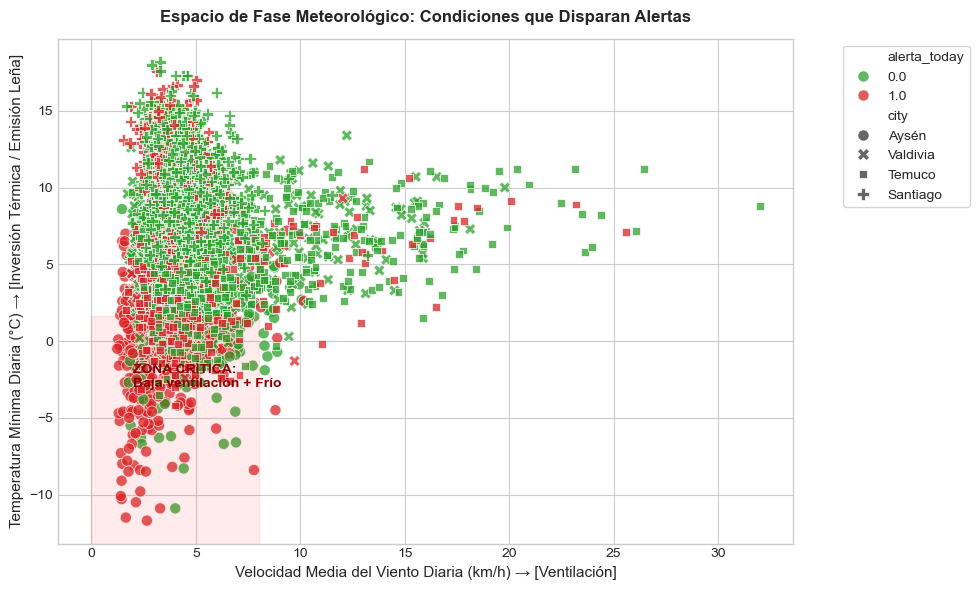

In [6]:
fig, ax = plt.subplots(figsize=(10, 6))

scatter = sns.scatterplot(
    data=df_gec,
    x="wind_mean_day_forecast",
    y="temp_min_day_forecast",
    hue="alerta_today",
    palette={0: "#2ca02c", 1: "#d62728"},
    style="city",
    s=65,
    alpha=0.75,
    ax=ax,
)

ax.set_title("Espacio de Fase Meteorológico: Condiciones que Disparan Alertas", fontweight="bold", pad=12)
ax.set_xlabel("Velocidad Media del Viento Diaria (km/h) → [Ventilación]")
ax.set_ylabel("Temperatura Mínima Diaria (°C) → [Inversión Térmica / Emisión Leña]")

# Anotación del cuadrante crítico
ax.axvspan(0, 8, ymin=0, ymax=0.45, color="red", alpha=0.08)
ax.text(2, -3, "ZONA CRÍTICA:\nBaja ventilación + Frío", color="darkred", fontweight="bold", fontsize=10)

# Corrección de la leyenda para que coincidan colores y símbolos
handles, labels = ax.get_legend_handles_labels()
# En Seaborn, el hue genera primero las categorías de alerta y luego el style genera las ciudades
ax.legend(loc="upper right", bbox_to_anchor=(1.25, 1.0), frameon=True)

plt.tight_layout()
plt.show()

  DISTRIBUCIÓN ESTACIONAL DE EPISODIOS CRÍTICOS (PM2.5 >= 50 µg/m³)


tasa_alerta_pct                             \
temporada Invierno (GEC: Mayo-Ago) Primavera-Verano (Sep-Abr)   
city                                                            
Aysén                    58.967391                   6.245059   
Santiago                 20.584145                   0.398089   
Temuco                   37.099024                   0.501672   
Valdivia                 10.928144                   0.328407   

                       dias_alerta                             \
temporada Invierno (GEC: Mayo-Ago) Primavera-Verano (Sep-Abr)   
city                                                            
Aysén                          434                         79   
Santiago                       148                          5   
Temuco                         266                          6   
Valdivia                        73                          4   

                     pm25_promedio                             
temporada Invierno (GEC: Mayo-Ago) Primavera-Verano (Sep-Abr)  
city                                                           
Aysén                    81.638151                  18.315191  
Santiago                  36.35754                  14.787773  
Temuco                   47.308208                  11.733919  
Valdivia                 23.024656                   6.933652

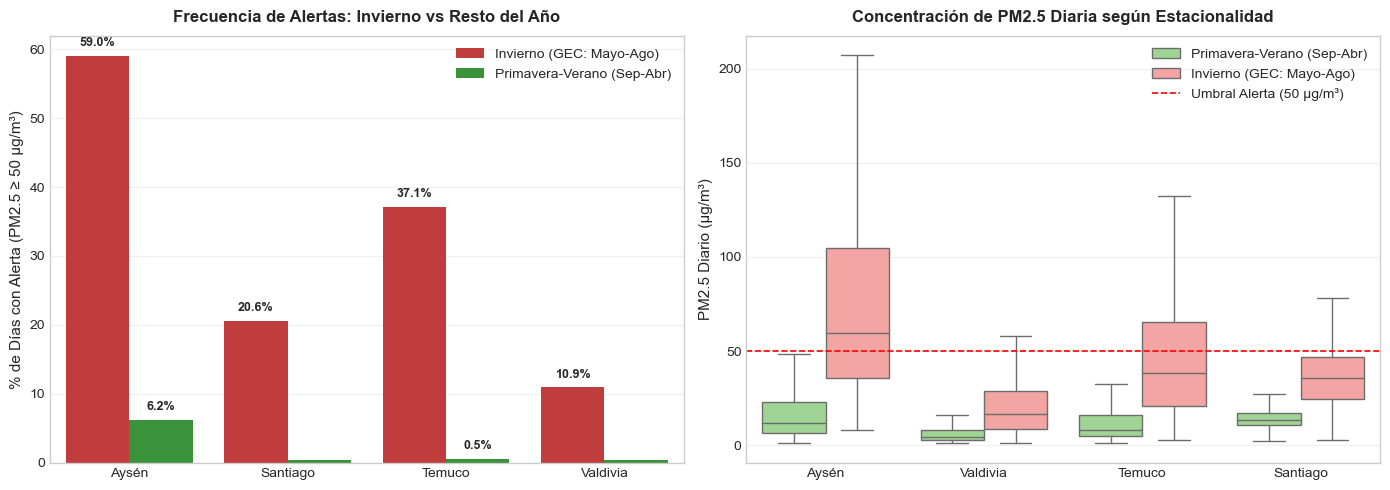

In [7]:
# ------------------------------------------------------------------------------
# Celda: Justificación Estacional — Comparación Invierno (GEC) vs Resto del Año
# ------------------------------------------------------------------------------
df_analisis = df_daily.copy()

if "alerta_today" not in df_analisis.columns:
    df_analisis["alerta_today"] = (df_analisis["pm25_mean_day"] >= 50.0).astype(
        int
    ).where(df_analisis["pm25_mean_day"].notna())

# Clasificación estacional: Invierno (GEC: Mayo a Agosto) vs Resto del Año
meses_gec = [5, 6, 7, 8]
df_analisis["temporada"] = np.where(
    df_analisis["month"].isin(meses_gec),
    "Invierno (GEC: Mayo-Ago)",
    "Primavera-Verano (Sep-Abr)",
)

# 1. Tabla Resumen Cuantitativa
resumen_temporada = (
    df_analisis.groupby(["city", "temporada"])
    .agg(
        dias_totales=("date_local", "count"),
        dias_alerta=("alerta_today", lambda x: (x == 1).sum()),
        pm25_promedio=("pm25_mean_day", "mean"),
        pm25_max=("pm25_mean_day", "max"),
    )
    .reset_index()
)

resumen_temporada["tasa_alerta_pct"] = (
    resumen_temporada["dias_alerta"] / resumen_temporada["dias_totales"]
) * 100

print("=" * 80)
print("  DISTRIBUCIÓN ESTACIONAL DE EPISODIOS CRÍTICOS (PM2.5 >= 50 µg/m³)")
print("=" * 80)
display(
    resumen_temporada.pivot(
        index="city",
        columns="temporada",
        values=["tasa_alerta_pct", "dias_alerta", "pm25_promedio"],
    ).round(1)
)

# 2. Visualización Gráfica
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Gráfico A: Comparativa de Tasa de Alertas (%) por Temporada
sns.barplot(
    data=resumen_temporada,
    x="city",
    y="tasa_alerta_pct",
    hue="temporada",
    palette={"Invierno (GEC: Mayo-Ago)": "#d62728", "Primavera-Verano (Sep-Abr)": "#2ca02c"},
    ax=axes[0],
)
axes[0].set_title(
    "Frecuencia de Alertas: Invierno vs Resto del Año",
    fontweight="bold",
    pad=10,
)
axes[0].set_ylabel("% de Días con Alerta (PM2.5 ≥ 50 µg/m³)")
axes[0].set_xlabel("")
axes[0].grid(axis="y", alpha=0.3)
axes[0].legend(title="")

for p in axes[0].patches:
    h = p.get_height()
    if h > 0.5:
        axes[0].annotate(
            f"{h:.1f}%",
            (p.get_x() + p.get_width() / 2.0, h + 1.0),
            ha="center",
            va="bottom",
            fontsize=9,
            fontweight="bold",
        )

# Gráfico B: Distribución de PM2.5 Diaria (Violinplot / Boxplot por Temporada)
sns.boxplot(
    data=df_analisis,
    x="city",
    y="pm25_mean_day",
    hue="temporada",
    palette={"Invierno (GEC: Mayo-Ago)": "#ff9896", "Primavera-Verano (Sep-Abr)": "#98df8a"},
    showfliers=False,
    ax=axes[1],
)
axes[1].axhline(50, color="red", ls="--", lw=1.2, label="Umbral Alerta (50 µg/m³)")
axes[1].set_title(
    "Concentración de PM2.5 Diaria según Estacionalidad",
    fontweight="bold",
    pad=10,
)
axes[1].set_ylabel("PM2.5 Diario (µg/m³)")
axes[1].set_xlabel("")
axes[1].grid(axis="y", alpha=0.3)
axes[1].legend(title="", loc="upper right")

plt.tight_layout()
plt.show()

NameError: name 'BASE_DIR' is not defined

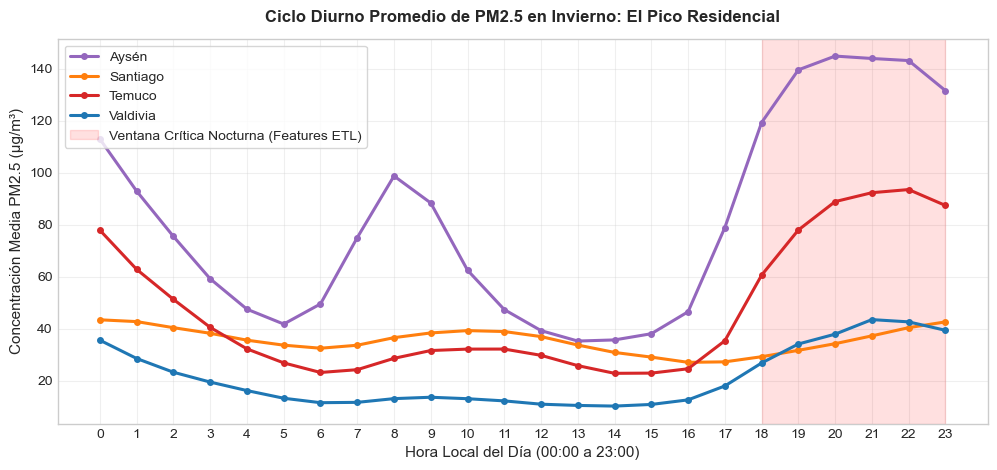

In [8]:
# ------------------------------------------------------------------------------
# Celda: Ciclo Diurno de PM2.5 (Perfil Horario Promedio en Invierno)
# ------------------------------------------------------------------------------
# Filtrar invierno (GEC)
df_h_gec = df_hourly[df_hourly["month"].isin([5, 6, 7, 8])].copy()

# Calcular el promedio de PM2.5 por ciudad y por hora del día
perfil_horario = (
    df_h_gec.groupby(["city", "hour_local"])["pm2_5"]
    .mean()
    .reset_index()
)

fig, ax = plt.subplots(figsize=(12, 5))

colores_ciudad = {
    "Santiago": "#ff7f0e",
    "Temuco": "#d62728",
    "Aysén": "#9467bd",
    "Valdivia": "#1f77b4",
}

for ciudad, grupo in perfil_horario.groupby("city"):
    ax.plot(
        grupo["hour_local"],
        grupo["pm2_5"],
        marker="o",
        ms=4,
        lw=2.2,
        label=ciudad,
        color=colores_ciudad.get(ciudad, "tab:gray"),
    )

# Resaltar la ventana nocturna usada en las features del modelo (18:00 a 23:00)
ax.axvspan(18, 23, color="red", alpha=0.12, label="Ventana Crítica Nocturna (Features ETL)")

ax.set_title("Ciclo Diurno Promedio de PM2.5 en Invierno: El Pico Residencial", fontweight="bold", pad=12)
ax.set_xlabel("Hora Local del Día (00:00 a 23:00)")
ax.set_ylabel("Concentración Media PM2.5 (µg/m³)")
ax.set_xticks(range(0, 24))
ax.grid(alpha=0.3)
ax.legend(loc="upper left", frameon=True)

# Guardar directo para el README
OUTPUTS_DIR = BASE_DIR / "outputs"
OUTPUTS_DIR.mkdir(parents=True, exist_ok=True)
fig.savefig(OUTPUTS_DIR / "ciclo_diurno_pm25.png", dpi=130, bbox_inches="tight")

plt.tight_layout()
plt.show()

NameError: name 'BASE_DIR' is not defined

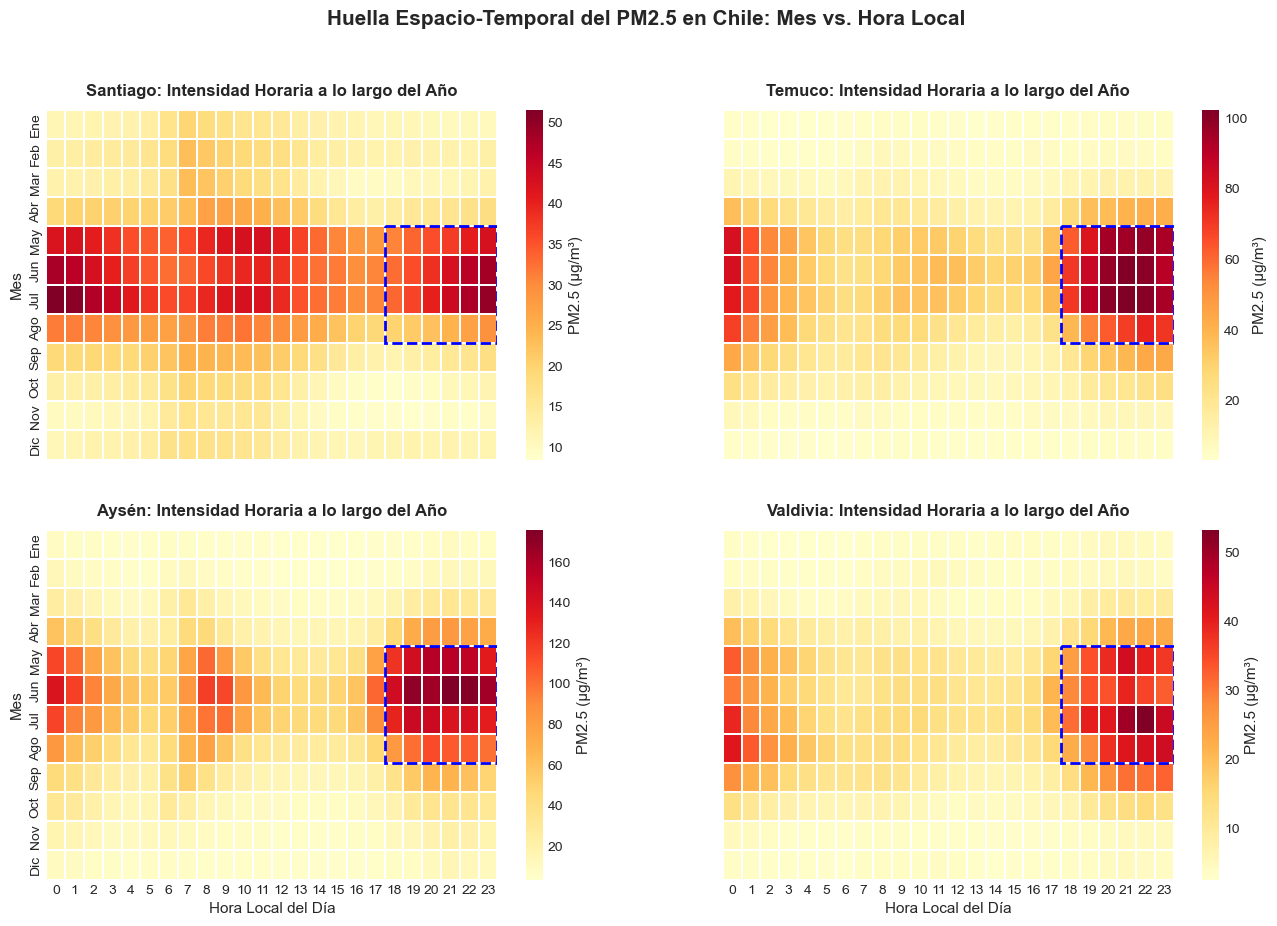

In [9]:
# ------------------------------------------------------------------------------
# Celda: Mapa de Calor (Mes vs. Hora del Día) por Ciudad
# ------------------------------------------------------------------------------
ciudades = ["Santiago", "Temuco", "Aysén", "Valdivia"]
nombres_meses = [
    "Ene", "Feb", "Mar", "Abr", "May", "Jun",
    "Jul", "Ago", "Sep", "Oct", "Nov", "Dic"
]

fig, axes = plt.subplots(2, 2, figsize=(16, 10), sharex=True, sharey=True)
axes = axes.flatten()

for i, ciudad in enumerate(ciudades):
    ax = axes[i]
    df_c = df_hourly[df_hourly["city"] == ciudad]

    # Matriz pivote: Filas = Mes (1-12), Columnas = Hora (0-23)
    pivote = df_c.pivot_table(
        index="month",
        columns="hour_local",
        values="pm2_5",
        aggfunc="mean",
    ).reindex(index=range(1, 13), columns=range(0, 24))

    pivote.index = nombres_meses

    # Heatmap con escala ajustada a la severidad de cada cuenca
    sns.heatmap(
        pivote,
        cmap="YlOrRd",
        ax=ax,
        cbar_kws={"label": "PM2.5 (µg/m³)"},
        linewidths=0.2,
        linecolor="white",
    )

    ax.set_title(f"{ciudad}: Intensidad Horaria a lo largo del Año", fontweight="bold", pad=10)
    ax.set_xlabel("Hora Local del Día" if i >= 2 else "")
    ax.set_ylabel("Mes" if i % 2 == 0 else "")

    # Marcar el cuadrante crítico: meses de invierno (Mayo-Ago) y horas nocturnas (18-23)
    # ymin=4 (Mayo, índice 4), ymax=8 (Agosto, índice 8), xmin=18, xmax=24
    rect = plt.Rectangle((18, 4), 6, 4, fill=False, edgecolor="blue", lw=2, ls="--")
    ax.add_patch(rect)

# Ajuste general y guardado
fig.suptitle(
    "Huella Espacio-Temporal del PM2.5 en Chile: Mes vs. Hora Local",
    fontsize=15,
    fontweight="bold",
    y=0.98,
)

OUTPUTS_DIR = BASE_DIR / "outputs"
OUTPUTS_DIR.mkdir(parents=True, exist_ok=True)
fig.savefig(OUTPUTS_DIR / "heatmap_mes_vs_hora.png", dpi=130, bbox_inches="tight")

plt.tight_layout()
plt.show()